In [1]:
!pip install autoviz

INFO: pip is looking at multiple versions of contourpy to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of scipy to determine which version is compatible with other requirements. This could take a while.
   ---------------------------------------- 0.0/36.5 MB ? eta -:--:--
   ------------------- -------------------- 17.6/36.5 MB 85.2 MB/s eta 0:00:01
   ---------------------------------------  36.4/36.5 MB 89.1 MB/s eta 0:00:01
   ---------------------------------------- 36.5/36.5 MB 75.0 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.18.1
    Uninstalling scipy-1.18.1:
      Successfully uninstalled scipy-1.18.1
  Attempting uninstall: contourpy
    Found existing installation: contourpy 1.4.0
    Uninstalling contourpy-1.4.0:
      Successfully uninstalled contourpy-1.4.0



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install "setuptools<70"


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
!pip install "xgboost<1.7"


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd

In [5]:
!pip install "pandas<2.2"


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
df = pd.read_csv('gii32_ act1_precios_carburantes_24.csv', encoding='utf-8')

In [7]:
df.columns = df.columns.str.strip()

In [8]:
provincia_buscada = 'GUADALAJARA'

In [9]:
df_guada = df[df['Provincia'] == provincia_buscada].copy()

In [10]:
print(f"Registros totales en el CSV: {len(df)}")

Registros totales en el CSV: 11865


In [11]:
print(f"Registros en la provincia de {provincia_buscada}: {len(df_guada)}")

Registros en la provincia de GUADALAJARA: 92


In [12]:
df_guada.head()

,Provincia,Municipio,Localidad,Código postal,Dirección,Precio gasolina 95 E5,Precio gasóleo A,Tipo venta,Tipo servicio,Rótulo
5344,GUADALAJARA,ALCOLEA DEL PINAR,ALCOLEA DEL PINAR,19260,"CR A-2, 132,2","1,589","1,569",P,A,REPSOL
5345,GUADALAJARA,ALCOLEA DEL PINAR,ALCOLEA DEL PINAR,19260,"CR A-2, 135","1,609","1,599",P,A,REPSOL
5346,GUADALAJARA,ALGORA,ALGORA,19268,AUTOVIA NORDESTE KM. 112,"1,679","1,639",P,A,CEPSA
5347,GUADALAJARA,ALMADRONES,ALMADRONES,19490,"AUTOVIA A-2 KM. 101,8","1,579","1,615",P,A,CEPSA
5348,GUADALAJARA,ALMADRONES,ALMADRONES,19490,AUTOVIA A-2 KM. 103,"1,579","1,615",P,A,CEPSA


In [13]:
valores_nulos = df_guada.isnull().sum()

In [14]:
print("\nValores faltantes por columna en Guadalajara:")
print(valores_nulos[valores_nulos > 0])


Valores faltantes por columna en Guadalajara:
Precio gasolina 95 E5    11
Precio gasóleo A          5
Tipo servicio             8
dtype: int64


In [15]:
print("\nEjemplo de estaciones con datos faltantes en el precio:")
df_nulos = df_guada[df_guada['Precio gasolina 95 E5'].isnull() | df_guada['Precio gasóleo A'].isnull()]
df_nulos.head()


Ejemplo de estaciones con datos faltantes en el precio:


,Provincia,Municipio,Localidad,Código postal,Dirección,Precio gasolina 95 E5,Precio gasóleo A,Tipo venta,Tipo servicio,Rótulo
5353,GUADALAJARA,ALOVERA,ALOVERA,19208,"CARRETERA A-2 KM 47,5 (SALIDA 48). CTRA. MADRI...",NaN,NaN,P,A,NATURGY
5371,GUADALAJARA,CABANILLAS DEL CAMPO,CABANILLAS DEL CAMPO,19171,POLIGONO FRANCISCO MEDINA Y MENDOZA PARCELA 10...,NaN,"1,356",R,A,ATA
5372,GUADALAJARA,CAMPILLO DE DUEÑAS,CAMPILLO DE DUEÑAS,19360,"DISEMINADO PG 15 PARCELA 29, S/N",NaN,"1,379",P,NaN,SDAD COOP CAMPILLO DE DUEÑAS
5377,GUADALAJARA,CUBILLO DE UCEDA (EL),CUBILLO DE UCEDA (EL),19186,"CALLE NUEVA, S/N",NaN,NaN,R,A,ASOC. AGRIC. Y GANA. CUBILLO DE UCEDA
5380,GUADALAJARA,GUADALAJARA,GUADALAJARA,19001,"CALLE FRANCISCO ARITIO, 16",NaN,"1,349",P,D,SIMON GRUP


In [16]:
df_guada['Precio gasolina 95 E5'] = pd.to_numeric(df_guada['Precio gasolina 95 E5'].str.replace(',', '.'), errors='coerce')
df_guada['Precio gasóleo A'] = pd.to_numeric(df_guada['Precio gasóleo A'].str.replace(',', '.'), errors='coerce')

print(df_guada[['Precio gasolina 95 E5', 'Precio gasóleo A']].dtypes)

Precio gasolina 95 E5    float64
Precio gasóleo A         float64
dtype: object


Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Shape of your Data Set loaded: (92, 10)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
  Printing up to 30 columns (max) in each category:
    Numeric Columns : ['Precio gasolina 95 E5', 'Precio gasóleo A']
    Integer-Categorical Columns: ['Código postal']
    String-Categorical Columns: ['Tipo servicio', 'Municipio', 'Localidad', 'Rótulo']
    Factor-Categorical Columns: []
    String-Boolean Columns: ['Tipo venta']
    Numeric-Boolean 

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
Provincia,object,0.000000,1,,,Possible Zero-variance or low information colum: drop before modeling step.
Municipio,object,0.000000,46,,,No issue
Localidad,object,0.000000,47,,,No issue
Código postal,int64,0.000000,46,19001.000000,19490.000000,No issue
Dirección,object,0.000000,96,,,No issue
Precio gasolina 95 E5,float64,11.956522,NA,1.253000,1.688000,"11 missing values. Impute them with mean, median, mode, or a constant value such as 123., Column has 12 outliers greater than upper bound (1.67) or lower than lower bound(1.47). Cap them or remove them."
Precio gasóleo A,float64,5.434783,NA,1.185000,1.639000,"5 missing values. Impute them with mean, median, mode, or a constant value such as 123., Column has 12 outliers greater than upper bound (1.71) or lower than lower bound(1.37). Cap them or remove them., Column has a high correlation with ['Precio gasolina 95 E5']. Consider dropping one of them."
Tipo venta,object,0.000000,2,,,No issue
Tipo servicio,object,8.695652,3,,,"8 missing values. Impute them with mean, median, mode, or a constant value such as 123., Mixed dtypes: has 2 different data types: object, float,"
Rótulo,object,0.000000,40,,,No issue


Number of All Scatter Plots = 3


[nltk_data] Downloading collection 'popular'
[nltk_data]    | 
[nltk_data]    | Downloading package cmudict to
[nltk_data]    |     C:\Users\Angel\AppData\Roaming\nltk_data...
[nltk_data]    |   Unzipping corpora\cmudict.zip.
[nltk_data]    | Downloading package gazetteers to
[nltk_data]    |     C:\Users\Angel\AppData\Roaming\nltk_data...
[nltk_data]    |   Unzipping corpora\gazetteers.zip.
[nltk_data]    | Downloading package genesis to
[nltk_data]    |     C:\Users\Angel\AppData\Roaming\nltk_data...
[nltk_data]    |   Unzipping corpora\genesis.zip.
[nltk_data]    | Downloading package gutenberg to
[nltk_data]    |     C:\Users\Angel\AppData\Roaming\nltk_data...
[nltk_data]    |   Unzipping corpora\gutenberg.zip.
[nltk_data]    | Downloading package inaugural to
[nltk_data]    |     C:\Users\Angel\AppData\Roaming\nltk_data...
[nltk_data]    |   Unzipping corpora\inaugural.zip.
[nltk_data]    | Downloading package movie_reviews to
[nltk_data]    |     C:\Users\Angel\AppData\Roaming\nl

Could not draw wordcloud plot for Dirección. 
Looks like you are missing some required data for this feature.

To download the necessary data, simply run

    python -m textblob.download_corpora

or use the NLTK downloader to download the missing data: http://nltk.org/data.html
If this doesn't fix the problem, file an issue at https://github.com/sloria/TextBlob/issues.

All Plots are saved in .\AutoViz_Plots\AutoViz
Time to run AutoViz = 15 seconds 


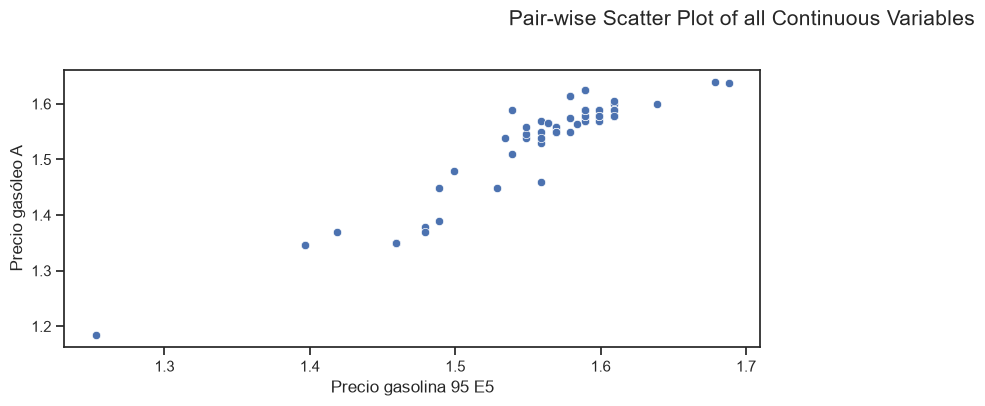

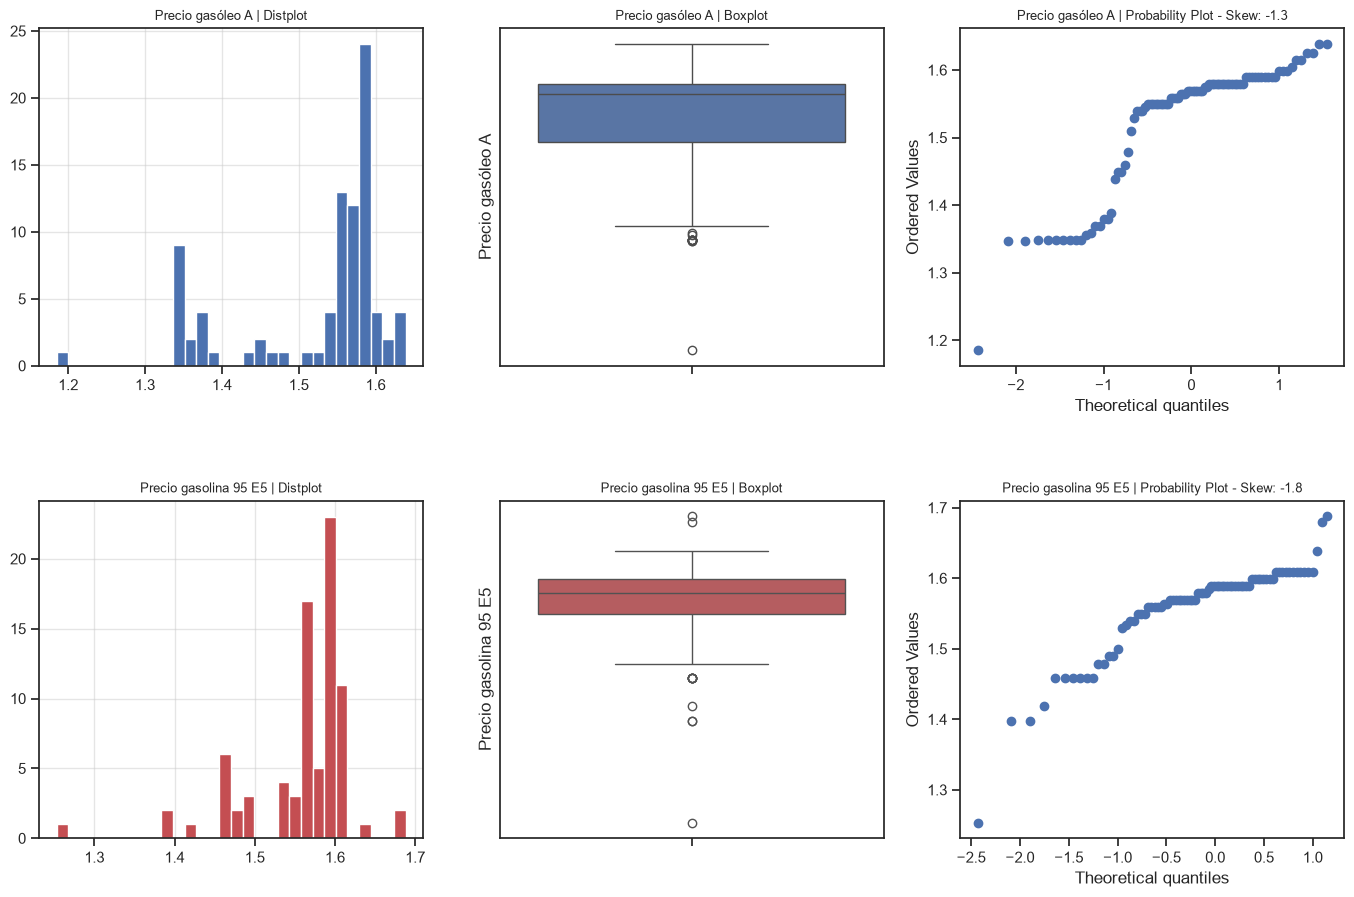

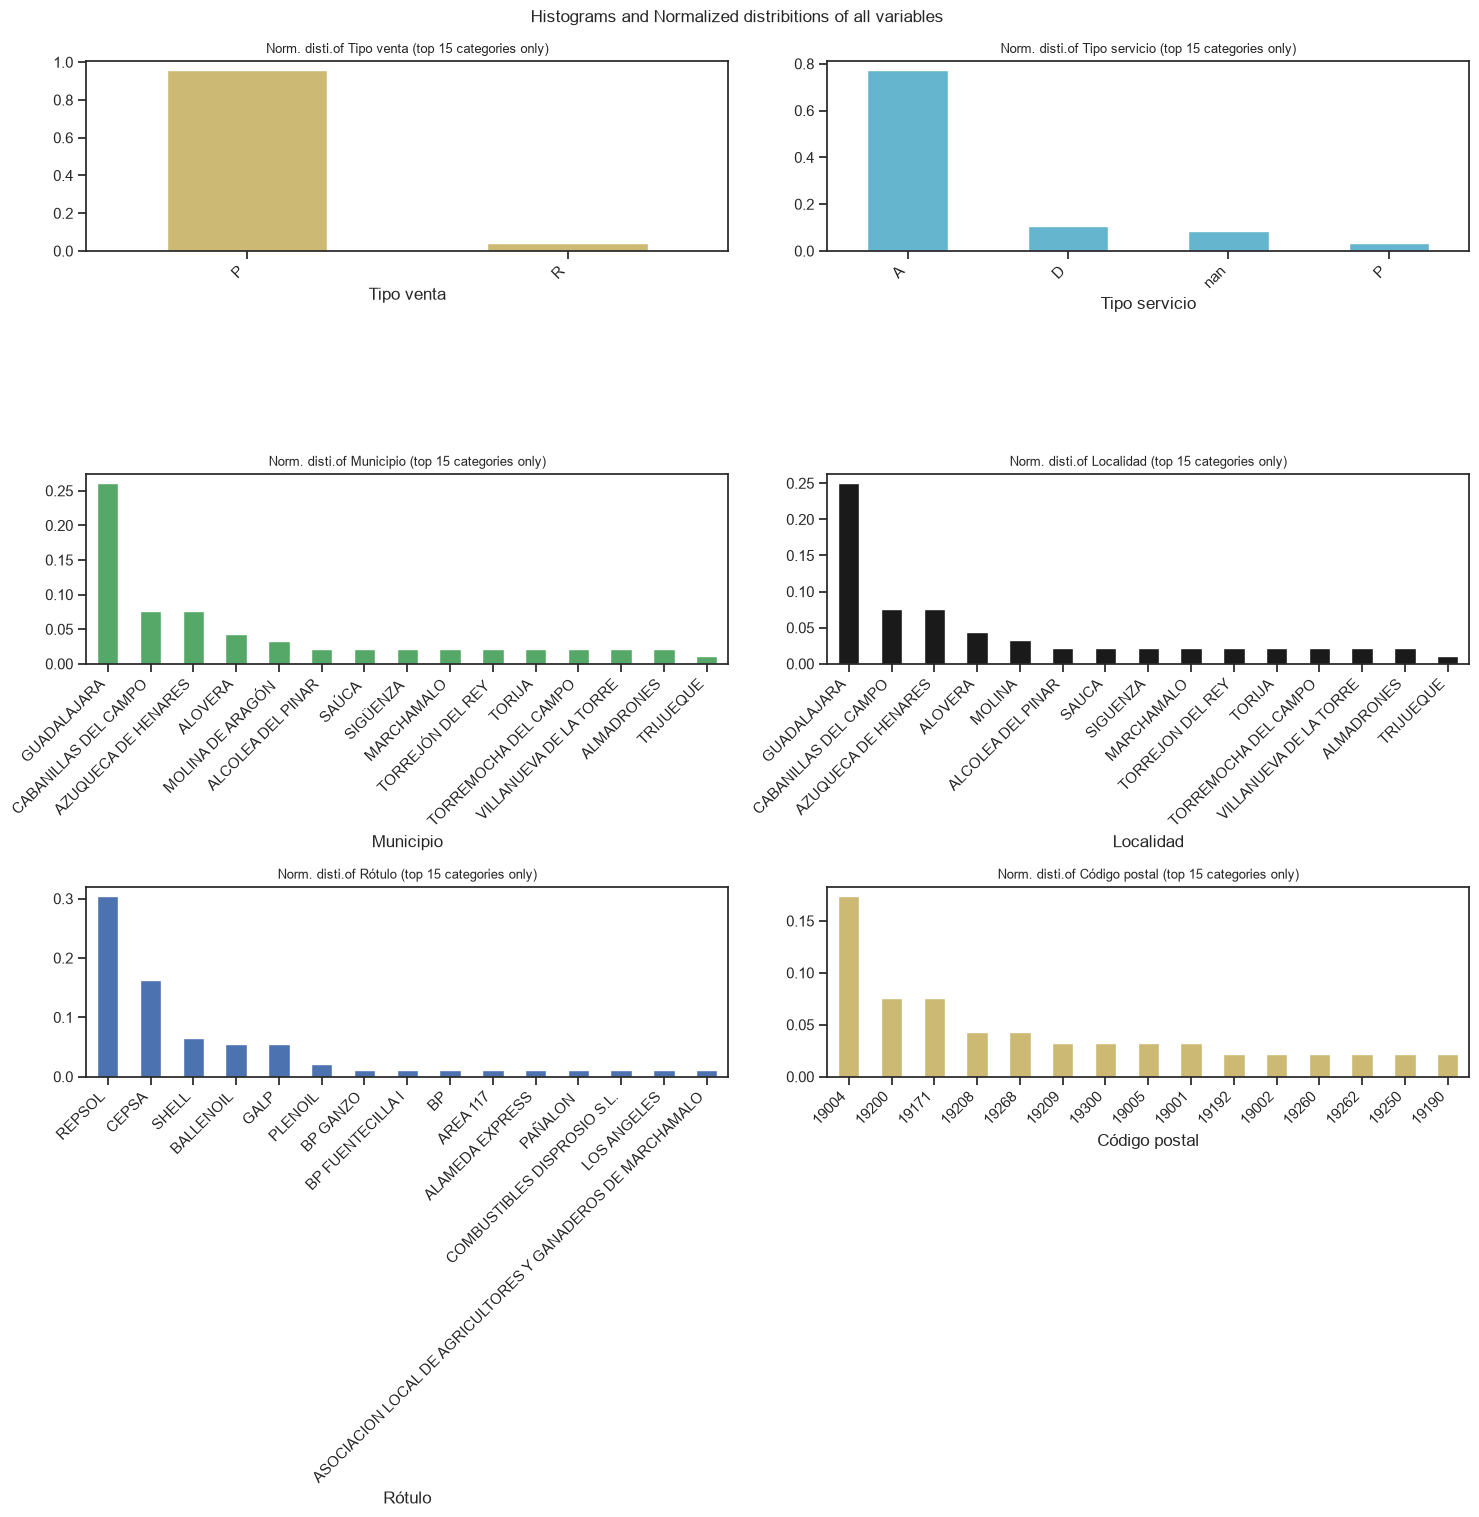

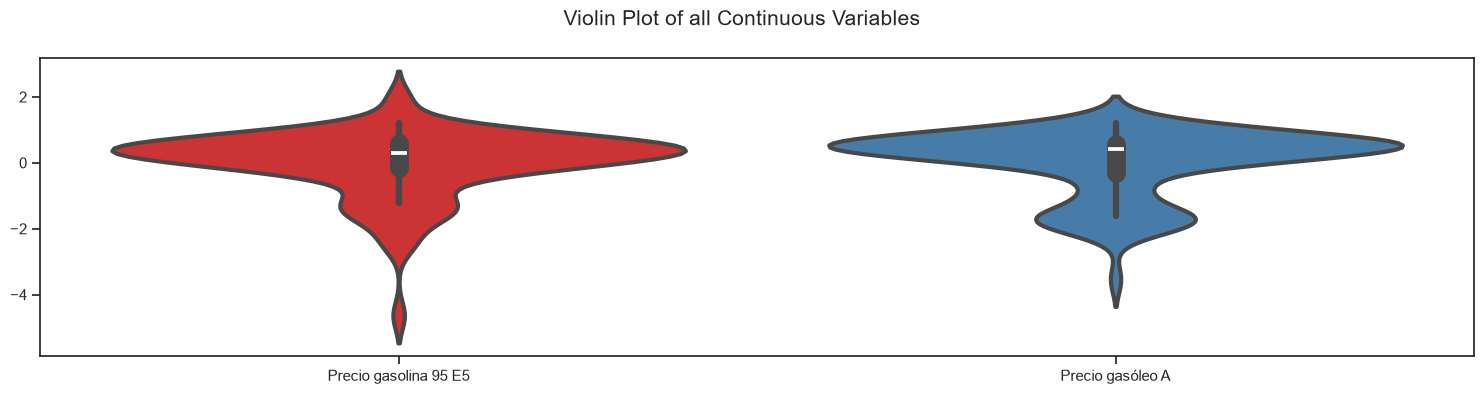

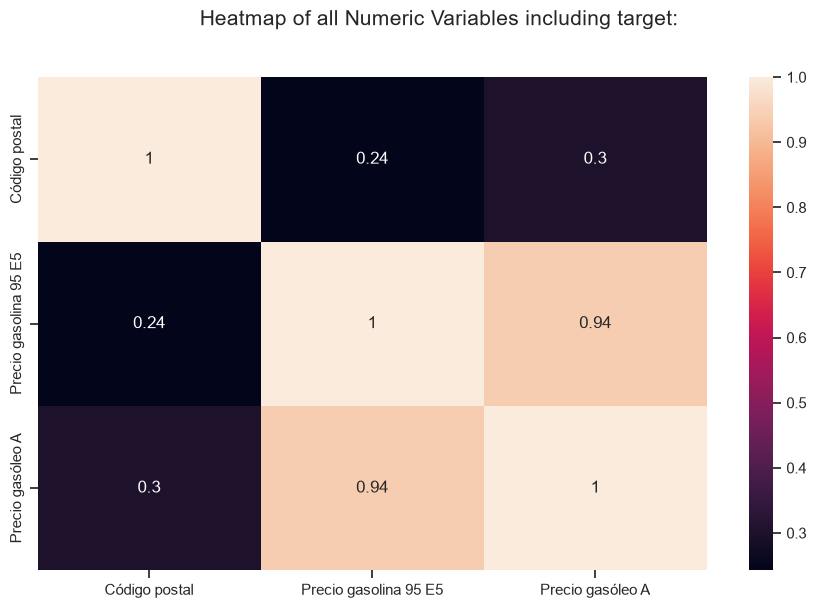

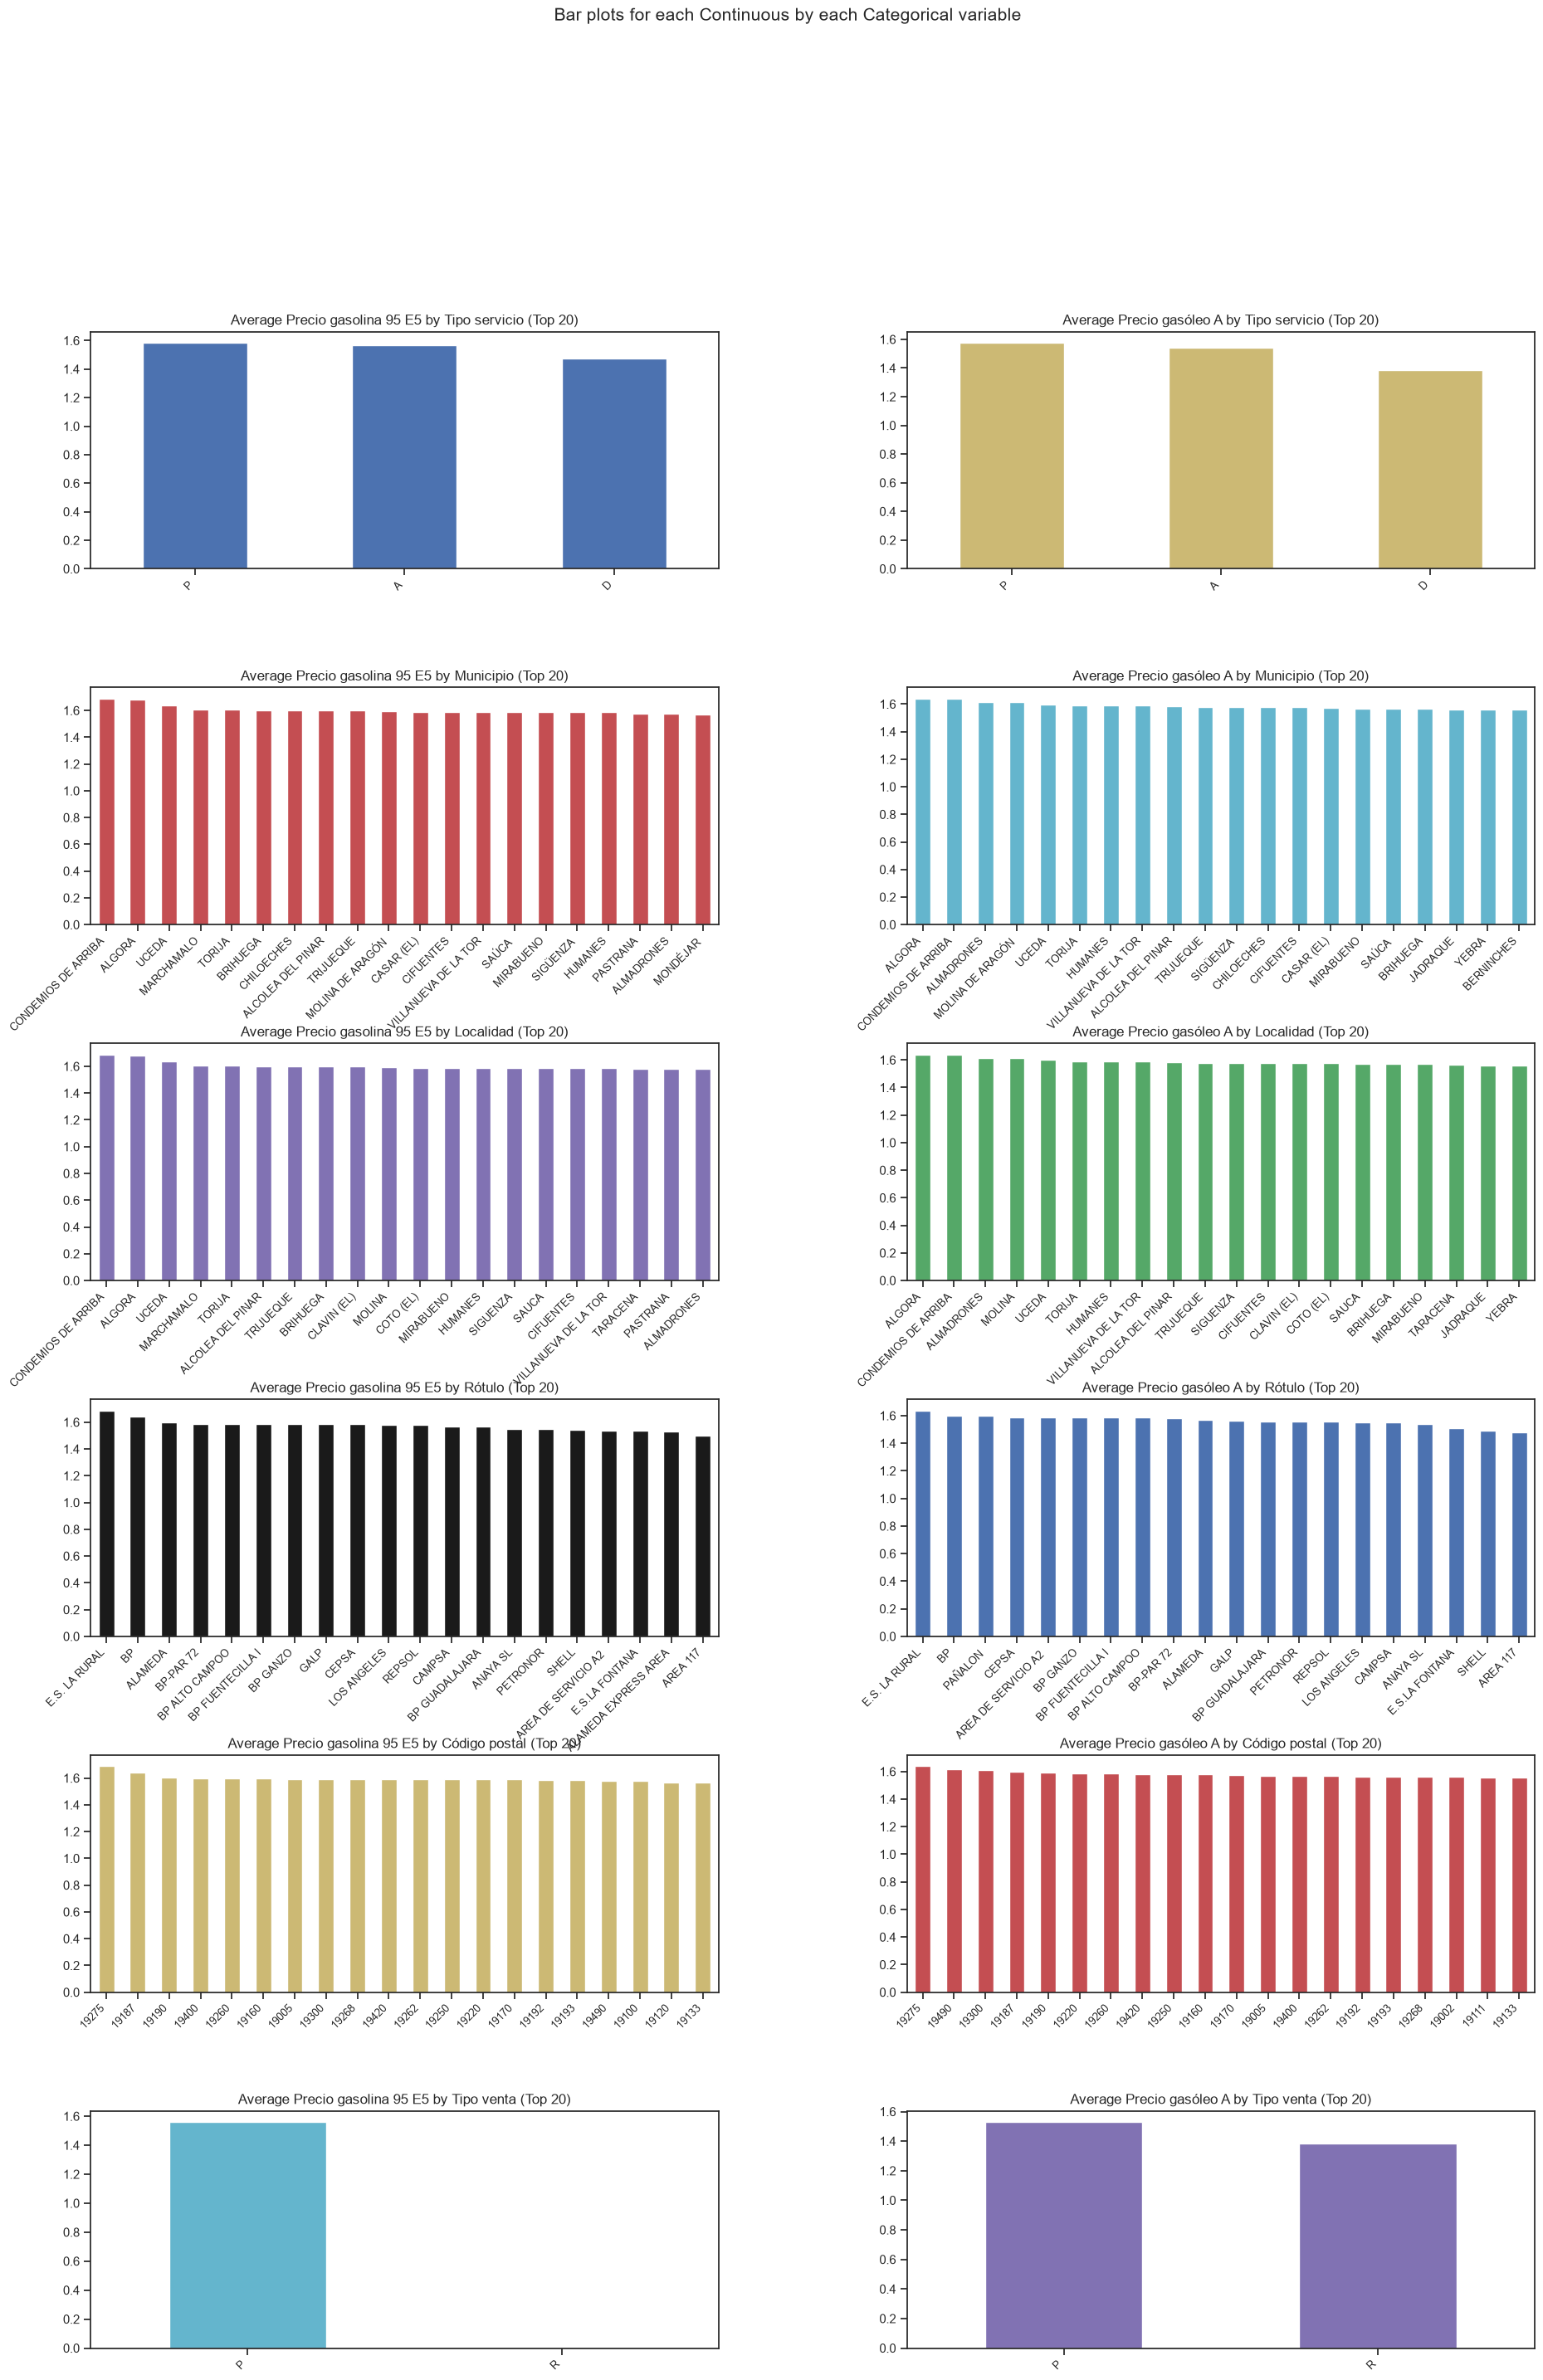

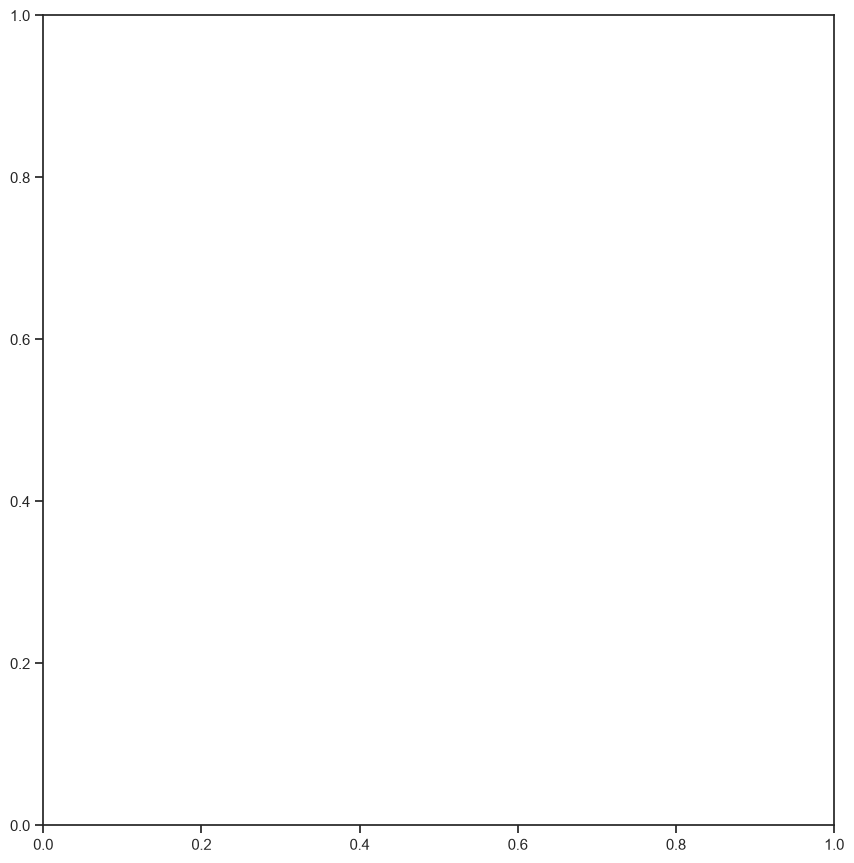

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from autoviz.AutoViz_Class import AutoViz_Class
%matplotlib inline

AV = AutoViz_Class()

report = AV.AutoViz(
    filename="", 
    sep=",", 
    depVar="", 
    dfte=df_guada, 
    header=0, 
    verbose=2,          
    lowess=False, 
    chart_format="png",  
    max_rows_analyzed=150, 
    max_cols_analyzed=10,
    save_plot_dir=None   
)

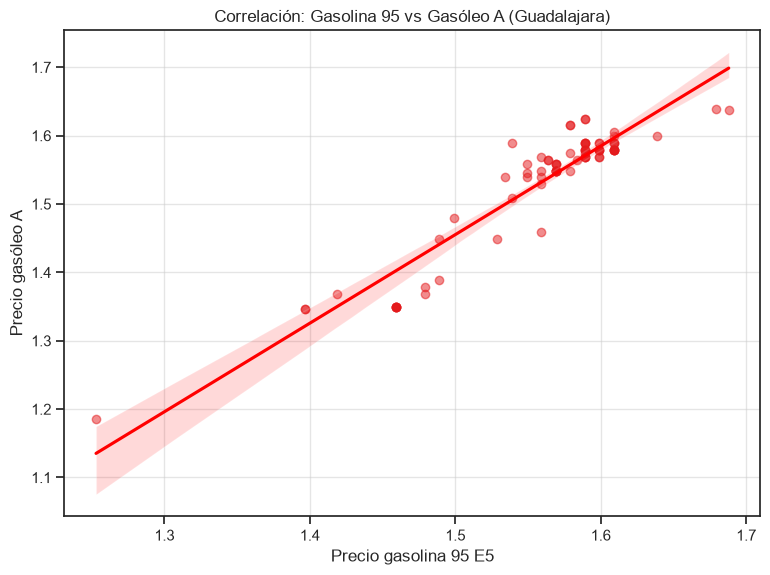

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.regplot(x='Precio gasolina 95 E5', y='Precio gasóleo A', data=df_guada, 
            scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title('Correlación: Gasolina 95 vs Gasóleo A (Guadalajara)')
plt.grid(True)
plt.show()

In [19]:
df_guada['Precio gasolina 95 E5'] = df_guada['Precio gasolina 95 E5'].fillna(df_guada['Precio gasolina 95 E5'].mean())
df_guada['Precio gasóleo A'] = df_guada['Precio gasóleo A'].fillna(df_guada['Precio gasóleo A'].mean())

print("Nulos tras la limpieza:")
print(df_guada[['Precio gasolina 95 E5', 'Precio gasóleo A']].isnull().sum())

Nulos tras la limpieza:
Precio gasolina 95 E5    0
Precio gasóleo A         0
dtype: int64


In [20]:
def analizar_outliers(df, columnas):
    lista_total_outliers = []
    
    for col in columnas:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        inf = Q1 - 1.5 * IQR
        sup = Q3 + 1.5 * IQR
        
        df_out = df[(df[col] < inf) | (df[col] > sup)].copy()
        df_out['Combustible_Outlier'] = col
        lista_total_outliers.append(df_out)
        
        print(f"--- Análisis para {col} ---")
        print(f"Rango normal: [{inf:.3f} - {sup:.3f}]")
        print(f"Detectados: {len(df_out)} outliers\n")

    return pd.concat(lista_total_outliers).drop_duplicates(subset=['Dirección', 'Rótulo'])

columnas_precios = ['Precio gasolina 95 E5', 'Precio gasóleo A']
df_outliers_total = analizar_outliers(df_guada, columnas_precios)

df_outliers_total[['Municipio', 'Rótulo', 'Precio gasolina 95 E5', 'Precio gasóleo A', 'Combustible_Outlier']]

--- Análisis para Precio gasolina 95 E5 ---
Rango normal: [1.514 - 1.634]
Detectados: 18 outliers

--- Análisis para Precio gasóleo A ---
Rango normal: [1.431 - 1.668]
Detectados: 17 outliers



,Municipio,Rótulo,Precio gasolina 95 E5,Precio gasóleo A,Combustible_Outlier
5346,ALGORA,CEPSA,1.679000,1.639,Precio gasolina 95 E5
5354,ALOVERA,BALLENOIL,1.397000,1.347,Precio gasolina 95 E5
5358,AZUQUECA DE HENARES,BALLENOIL,1.397000,1.347,Precio gasolina 95 E5
5359,AZUQUECA DE HENARES,SHELL,1.489000,1.449,Precio gasolina 95 E5
5368,CABANILLAS DEL CAMPO,DST CABANILLAS,1.479000,1.379,Precio gasolina 95 E5
5370,CABANILLAS DEL CAMPO,BALLENOIL,1.419000,1.369,Precio gasolina 95 E5
5376,CONDEMIOS DE ARRIBA,E.S. LA RURAL,1.688000,1.638,Precio gasolina 95 E5
5382,GUADALAJARA,BALLENOIL,1.459000,1.349,Precio gasolina 95 E5
5391,GUADALAJARA,SHELL,1.479000,1.369,Precio gasolina 95 E5
5392,GUADALAJARA,BALLENOIL,1.459000,1.349,Precio gasolina 95 E5


In [21]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_guada[['Gasolina_95_Norm', 'Gasoleo_A_Norm']] = scaler.fit_transform(df_guada[['Precio gasolina 95 E5', 'Precio gasóleo A']])

print("Valores originales vs Normalizados:")
print(df_guada[['Precio gasolina 95 E5', 'Gasolina_95_Norm']].head())
print("\nValores originales vs Normalizados:")
print(df_guada[['Precio gasóleo A', 'Gasoleo_A_Norm']].head())

Valores originales vs Normalizados:
      Precio gasolina 95 E5  Gasolina_95_Norm
5344          1.589              0.772414    
5345          1.609              0.818391    
5346          1.679              0.979310    
5347          1.579              0.749425    
5348          1.579              0.749425    

Valores originales vs Normalizados:
      Precio gasóleo A  Gasoleo_A_Norm
5344        1.569          0.845815   
5345        1.599          0.911894   
5346        1.639          1.000000   
5347        1.615          0.947137   
5348        1.615          0.947137   


In [22]:
print("--- ANTES DE LA LIMPIEZA ---")
tipos_antes = df_guada['Tipo servicio'].apply(type).unique()
print(f"Tipos de datos detectados en 'Tipo servicio': {tipos_antes}")

df_guada['Tipo servicio'] = df_guada['Tipo servicio'].astype(str)

print("\n--- DESPUÉS DE LA LIMPIEZA ---")
tipos_despues = df_guada['Tipo servicio'].apply(type).unique()
print(f"Tipos de datos detectados en 'Tipo servicio': {tipos_despues}")

print("\nEjemplo de valores procesados:")
print(df_guada['Tipo servicio'].unique())

--- ANTES DE LA LIMPIEZA ---
Tipos de datos detectados en 'Tipo servicio': [<class 'str'> <class 'float'>]

--- DESPUÉS DE LA LIMPIEZA ---
Tipos de datos detectados en 'Tipo servicio': [<class 'str'>]

Ejemplo de valores procesados:
['A' 'D' 'nan' 'P']
